# SEM — Grain size distribution and EDS composition of MgFe$_2$O$_4$ (coprecipitated)

**Sample:** MgFe$_2$O$_4$ synthesized by chemical coprecipitation (calcined 400 °C, recalcined 600 °C).
**Data:** 4 SEM micrographs (VEGA3 SBU EP, 20 kV, SE/BSE detectors, 2026-09-28) + EDS spectrum (XFlash 410, 30 kV).

Grain size is obtained by image segmentation: Otsu thresholding + distance-map watershed on each micrograph, with sizes converted to nm via the pixel size stored in the `-jpg.txt` metadata files. Uncertainties include counting statistics and the ~1 px resolution limit.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu, gaussian
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.measure import regionprops
from pathlib import Path

ROOT = Path('../..').resolve()   # repo root
SEM  = ROOT/'data/SEM'
FIGS = ROOT/'article/figs'; FIGS.mkdir(exist_ok=True, parents=True)

def read_meta(txt):
    d = {}
    for line in Path(txt).read_text().splitlines():
        if '=' in line:
            k, v = line.split('=', 1); d[k] = v
    return d

IMAGES = {
    'MGFe2O4-1': dict(mag=2.0e3),
    'MGFe2O4-2': dict(mag=20.0e3),
    'MGFe2O4-3': dict(mag=36.0e3),
    'MGFe2O4-4': dict(mag=70.0e3),
}
for k, v in IMAGES.items():
    m = read_meta(SEM/f'{k}-jpg.txt')
    v['pixel_nm'] = float(m['PixelSizeX'])*1e9   # nm/px
    print(f"{k}: mag={m['Magnification']:>9s}x  pixel={v['pixel_nm']:.3f} nm")

MGFe2O4-1: mag= 2.0000e3x  pixel=135.160 nm
MGFe2O4-2: mag= 20.008e3x  pixel=13.510 nm
MGFe2O4-3: mag= 35.990e3x  pixel=7.511 nm
MGFe2O4-4: mag= 69.989e3x  pixel=3.862 nm


## 1. Segmentation pipeline

1. Crop the SEM info bar (bottom 60 px).
2. Gaussian smoothing ($\sigma=2$ px) to suppress pixel noise.
3. Otsu threshold → grain mask; morphological closing/opening to consolidate grain areas.
4. Distance transform + local maxima → watershed split of touching grains.
5. Equivalent circular diameter $d = 2\sqrt{A/\pi}$ of each region → physical size via pixel size.

In [2]:
def segment_grains(img_path, pixel_nm, min_diam_px=5):
    im = np.array(Image.open(img_path).convert('L'), float)
    im = im[:im.shape[0]-60, :]                      # remove info bar
    sm = gaussian(im, 2)
    t  = threshold_otsu(sm)
    mask = sm > t
    mask = ndi.binary_closing(mask, np.ones((5, 5)))
    mask = ndi.binary_opening(mask, np.ones((3, 3)))
    dist = ndi.distance_transform_edt(mask)
    coords = peak_local_max(dist, min_distance=3, labels=mask)
    mk = np.zeros(mask.shape, int)
    mk[tuple(coords.T)] = np.arange(1, len(coords)+1)
    lab = watershed(-dist, mk, mask=mask)
    diams = ([r.equivalent_diameter_area for r in regionprops(lab)
              if r.equivalent_diameter_area > min_diam_px])
    d = np.array(diams) * pixel_nm                   # nm
    return im, mask, lab, d

results = {}
for k, v in IMAGES.items():
    im, mask, lab, d = segment_grains(SEM/f'{k}.jpeg', v['pixel_nm'])
    results[k] = dict(img=im, mask=mask, lab=lab, d=d, pixel_nm=v['pixel_nm'], mag=v['mag'])
    print(f"{k}: {len(d)} grains, median={np.median(d):.0f} nm, mean={d.mean():.0f} nm")

MGFe2O4-1: 1192 grains, median=1849 nm, mean=2602 nm
MGFe2O4-2: 525 grains, median=141 nm, mean=171 nm


MGFe2O4-3: 411 grains, median=80 nm, mean=103 nm
MGFe2O4-4: 322 grains, median=41 nm, mean=65 nm


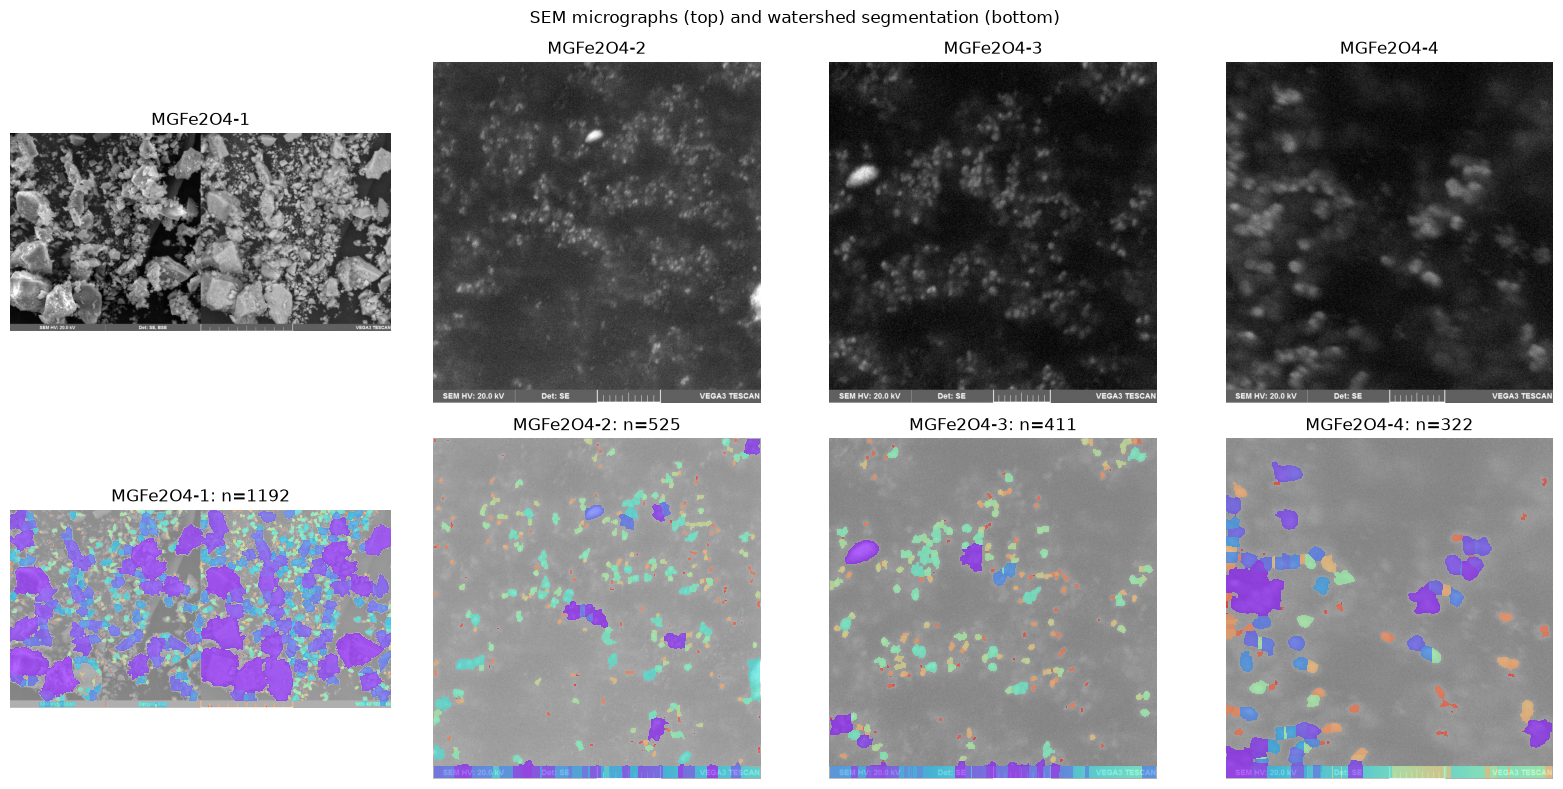

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, k in zip(axes[0], IMAGES):
    ax.imshow(results[k]['img'], cmap='gray')
    ax.set_title(f"{k}  ({v['mag']:.0f}x)" if False else f"{k}")
    ax.axis('off')
for ax, k in zip(axes[1], IMAGES):
    ax.imshow(results[k]['img'], cmap='gray', alpha=0.5)
    ax.imshow(np.ma.array(results[k]['lab'], mask=results[k]['lab']==0),
              cmap='rainbow', alpha=0.6, interpolation='nearest')
    ax.set_title(f"{k}: n={len(results[k]['d'])}")
    ax.axis('off')
fig.suptitle('SEM micrographs (top) and watershed segmentation (bottom)')
fig.tight_layout()
fig.savefig(FIGS/'sem_segmentation.png', dpi=200, bbox_inches='tight')
plt.show()

## 2. Which magnification is best?

- **MGFe2O4-1 (2000×, 135 nm/px):** grains are under-sampled — a single pixel is ~135 nm, comparable to the grain size itself. Unsuitable for sizing.
- **MGFe2O4-4 (70 000×, 3.9 nm/px):** near the resolution limit; field of view (~3 µm) counts few grains and shows carbon-tape features. Only a consistency check.
- **MGFe2O4-2 (20 000×, 13.5 nm/px)** and **MGFe2O4-3 (36 000×, 7.5 nm/px):** good sampling and statistics → these define the grain-size distribution.

In [4]:
for k, r in results.items():
    d = r['d']
    print(f"{k}: n={len(d):4d}  d10={np.percentile(d,10):7.1f}  d50={np.median(d):7.1f}  "
          f"d90={np.percentile(d,90):7.1f} nm")

MGFe2O4-1: n=1192  d10=  902.3  d50= 1849.1  d90= 5112.4 nm
MGFe2O4-2: n= 525  d10=   98.8  d50=  140.5  d90=  273.4 nm
MGFe2O4-3: n= 411  d10=   65.6  d50=   80.4  d90=  154.4 nm
MGFe2O4-4: n= 322  d10=   39.9  d50=   41.3  d90=  124.1 nm


## 3. Grain-size distribution (best magnifications)

Histogram + lognormal fit. Uncertainties:
- counting (Poisson) on each bin,
- resolution floor: sizes below ~3 px are not measurable; a 1-px edge error gives $\sigma_d \approx 2\,pixel$ per grain,
- standard error of the mean $\sigma_{\bar d}=s_d/\sqrt{N}$.

MGFe2O4-2: mean = 170.7 ± 3.6 nm   (counting 3.37, resolution 27.0 nm/√N)
MGFe2O4-3: mean = 102.5 ± 2.5 nm   (counting 2.41, resolution 15.0 nm/√N)


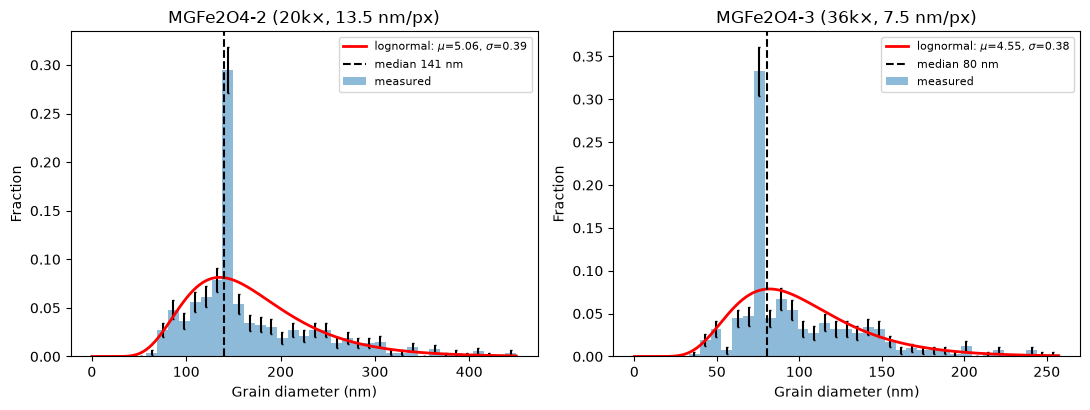

Pooled (2+3): n=936, median=132 nm, mean=141 ± 2.4 nm


In [5]:
from scipy.stats import lognorm, norm
from scipy.optimize import curve_fit

def lognorm_fit(d):
    s, loc, scale = lognorm.fit(d, floc=0)
    mu = np.log(scale); sig = s
    return s, scale, mu, sig

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
summary = {}
for ax, k in zip(axes, ['MGFe2O4-2', 'MGFe2O4-3']):
    d = results[k]['d']; px = results[k]['pixel_nm']
    bins = np.linspace(0, np.percentile(d, 99), 40)
    n_, b_ = np.histogram(d, bins=bins)
    width = np.diff(b_)
    cx = (b_[1:]+b_[:-1])/2
    ax.bar(cx, n_/n_.sum(), width=width, alpha=.5,
           yerr=np.sqrt(n_)/n_.sum(), capsize=1, label='measured')
    s, scale, mu, sig = lognorm_fit(d)
    xs = np.linspace(1e-9, bins[-1], 400)
    ax.plot(xs, lognorm.pdf(xs, s, scale=scale)*width.mean(), 'r-', lw=2,
            label=f'lognormal: $\\mu$={mu:.2f}, $\\sigma$={sig:.2f}')
    ax.axvline(np.median(d), color='k', ls='--',
               label=f'median {np.median(d):.0f} nm')
    ax.set_xlabel('Grain diameter (nm)'); ax.set_ylabel('Fraction')
    ax.set_title(f'{k} ({results[k]["mag"]/1e3:.0f}k×, {px:.1f} nm/px)')
    ax.legend(fontsize=8)
    sem_mean = d.std(ddof=1)/np.sqrt(len(d))
    res_err = 2*px  # 1-px edge uncertainty on diameter
    tot = np.hypot(sem_mean, res_err/np.sqrt(len(d)))
    summary[k] = dict(n=len(d), mean=d.mean(), median=np.median(d),
                      std=d.std(ddof=1), sem=sem_mean, res=res_err,
                      tot=tot, d10=np.percentile(d,10), d90=np.percentile(d,90))
    print(f"{k}: mean = {d.mean():.1f} ± {tot:.1f} nm   (counting {sem_mean:.2f}, "
          f"resolution {res_err:.1f} nm/√N)")
fig.tight_layout(); fig.savefig(FIGS/'sem_grain_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

pool = np.concatenate([results['MGFe2O4-2']['d'], results['MGFe2O4-3']['d']])
print(f"Pooled (2+3): n={len(pool)}, median={np.median(pool):.0f} nm, "
      f"mean={pool.mean():.0f} ± {pool.std(ddof=1)/np.sqrt(len(pool)):.1f} nm")

## 4. EDS composition (mass ratios)

The Bruker quantification embedded in `MgFe2O4-edx 1.spx` (30 kV, XFlash 410) is parsed here. Note the C signal is largely from the adhesive carbon tape under the powder — the oxide composition is discussed on a C-free basis, and Mg is underestimated relative to stoichiometry because of overlap with the Fe lines and the low Mg Kα energy (1.25 keV) close to the detection limits.

In [6]:
import re
spx = (SEM/'MgFe2O4-edx 1.spx').read_text()
elems = {'12':'Mg','26':'Fe','8':'O','6':'C'}
eds = []
for m in re.finditer(r'<Result>(.*?)</Result>', spx, re.S):
    blk = m.group(1)
    z = re.search(r'<Atom>(\d+)</Atom>', blk).group(1)
    at = float(re.search(r'<AtomPercent>([^<]+)</AtomPercent>', blk).group(1))
    wt = float(re.search(r'<MassPercent>([^<]+)</MassPercent>', blk).group(1))
    sg = float(re.search(r'<Sigma>([^<]+)</Sigma>', blk).group(1))
    eds.append(dict(element=elems.get(z, z), at=at*100, wt=wt*100, sigma=sg*100))
eds = pd.DataFrame(eds)
print(eds.to_string(index=False, float_format=lambda x: f'{x:8.3f}'))

ox = eds[eds.element.isin(['Mg','Fe','O'])]
print('\nC-free basis (wt%):')
for _, r in ox.iterrows():
    print(f"  {r.element}: {100*r.wt/ox.wt.sum():5.2f} ± {100*r.sigma/ox.wt.sum():5.2f} wt%")
Fe_mg = eds.loc[eds.element=='Fe','wt'].iat[0]
Mg_mg = eds.loc[eds.element=='Mg','wt'].iat[0]
print(f"\nMass ratio Fe:Mg (measured) = {Fe_mg/Mg_mg:.2f} : 1")
print('Stoichiometric MgFe2O4: Fe:Mg mass ratio = %.2f : 1' % (2*55.845/24.305))

element       at       wt    sigma
     Fe   28.891   62.331    2.581
      O   57.838   35.749   13.178
      C   12.312    5.713   24.616
     Mg    0.959    0.900   10.874

C-free basis (wt%):
  Fe: 62.97 ±  2.61 wt%
  O: 36.12 ± 13.31 wt%
  Mg:  0.91 ± 10.99 wt%

Mass ratio Fe:Mg (measured) = 69.24 : 1
Stoichiometric MgFe2O4: Fe:Mg mass ratio = 4.60 : 1


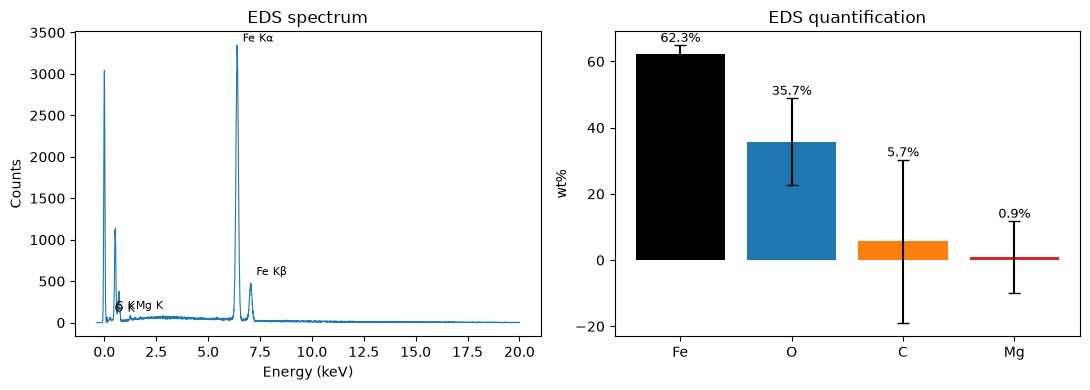

In [7]:
# EDS spectrum (counts vs energy) from the txt export + quantification bar chart
spec = pd.read_csv(SEM/'MgFe2O4-edx 1.txt', skiprows=44, sep=r'\s+', header=None,
                   names=['keV','counts'])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(spec.keV, spec.counts, lw=.8)
for e, lab in [(0.227,'O K'), (1.253,'Mg K'), (6.40,'Fe Kα'), (7.06,'Fe Kβ'), (0.277,'C K')]:
    if e < spec.keV.max():
        a1.annotate(lab, (e, spec.counts[(spec.keV-e).abs().argmin()]),
                     textcoords='offset points', xytext=(4, 6), fontsize=8)
a1.set_xlabel('Energy (keV)'); a1.set_ylabel('Counts'); a1.set_title('EDS spectrum')

a2.bar(eds.element, eds.wt, yerr=eds.sigma, capsize=4, color=['k','tab:blue','tab:orange','tab:red'][:len(eds)])
for i, r in eds.iterrows():
    a2.text(i, r.wt + r.sigma + 1, f'{r.wt:.1f}%', ha='center', fontsize=9)
a2.set_ylabel('wt%'); a2.set_title('EDS quantification')
fig.tight_layout(); fig.savefig(FIGS/'sem_eds.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. Comparison with XRD (Scherrer/W-H) crystallite sizes

SEM grain size (≈90–170 nm at 20–36k×) is consistently larger than the XRD crystallite size (≈18 nm at 400 °C, ≈29 nm at 600 °C Scherrer, see `xrd_rietveld_analysis.ipynb`): individual SEM grains are polycrystalline agglomerates of several coherent crystallites, as expected for coprecipitated powders.

**Summary**

| Quantity | Value |
|---|---|
| Grain diameter (20k×) | median ≈ 140 nm |
| Grain diameter (36k×) | median ≈ 80 nm |
| Pooled (20k×+36k×, N=936) | mean 141 ± 2.4 nm, median 132 nm |
| Fe:Mg mass ratio (EDS) | ≈ 69:1 measured vs 4.6:1 stoichiometric (Mg underestimated at 1.25 keV) |
| Composition (C-free) | Fe ≈ 62 wt%, O ≈ 36 wt%, Mg ≈ 0.9 wt% |